# Pertemuan 11 — Teori Dasar: Support Vector Machine (SVM)

Notebook ini membahas teori dasar **Support Vector Machine (SVM)**, algoritma klasifikasi yang bekerja dengan mencari pemisah terbaik antar kelas melalui konsep **margin** maksimum. Pembahasan mencakup hard margin, soft margin, parameter **C**, **kernel trick**, dan pengaruh parameter **gamma**.

Sumber: [JS11 - Klasifikasi 2](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2).

## 1. Apa itu SVM?

SVM mencari garis atau bidang pemisah terbaik (*optimal hyperplane*) antara dua kelas. "Terbaik" berarti pemisah tersebut memiliki **margin terlebar** terhadap titik data terdekat dari masing-masing kelas. Titik-titik terdekat itu disebut **support vectors** karena menentukan posisi garis pemisah. Dengan margin yang lebar, model menjadi lebih tahan terhadap noise dan lebih mampu melakukan generalisasi.

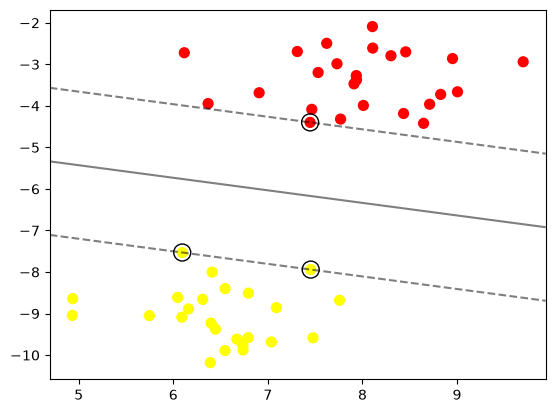

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

def plot_svc(model, ax=None):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, Xg = np.meshgrid(y, x)
    xy = np.vstack([Xg.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(Xg.shape)
    ax.contour(Xg, Y, P, colors='k', levels=[-1, 0, 1],
               alpha=0.5, linestyles=['--', '-', '--'])
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=150, linewidth=1, facecolors='none', edgecolors='k')

X, y = make_blobs(n_samples=50, centers=2, random_state=6, cluster_std=0.7)
model = SVC(kernel='linear', C=1E10).fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc(model)
plt.show()

Garis tegas di tengah adalah *hyperplane*, sedangkan dua garis putus-putus adalah margin. Titik yang berada tepat pada garis margin adalah **support vectors**. Semakin lebar margin, semakin percaya diri model dalam memisahkan kedua kelas.

## 2. Margin: Hard Margin, Soft Margin, dan Parameter C

**Hard margin** menuntut semua titik berada di sisi yang benar tanpa kesalahan, tetapi tidak realistis jika ada outlier. **Soft margin** memperbolehkan sebagian titik melanggar batas dengan penalti. Parameter **C** mengendalikan keseimbangan antara margin yang lebar dan jumlah pelanggaran: nilai C besar membuat model lebih ketat (risiko overfitting), sedangkan nilai C kecil memberi kelonggaran (risiko underfitting).

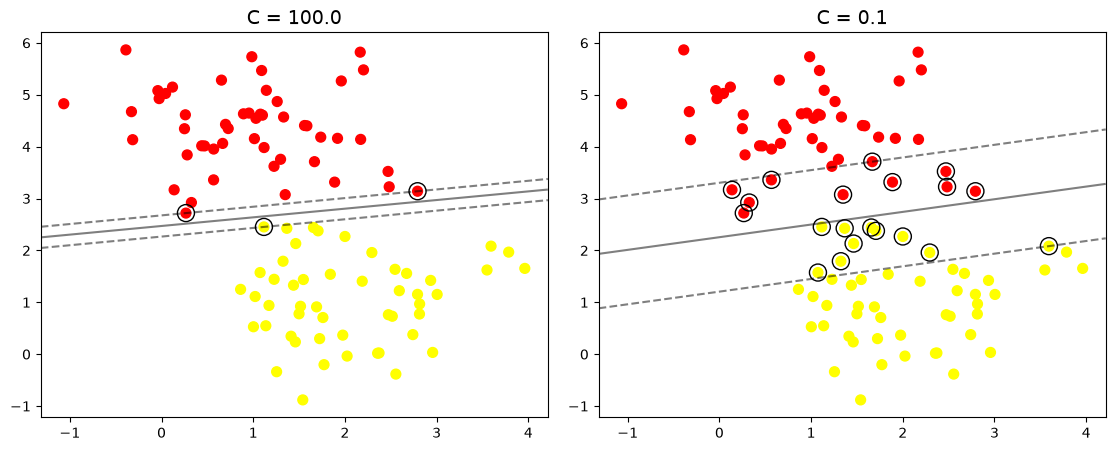

In [2]:
X, y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, C in zip(ax, [100.0, 0.1]):
    m = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc(m, axi)
    axi.set_title('C = {0}'.format(C), size=14)
plt.show()

Dengan C besar (kiri) model berusaha mengklasifikasikan semua titik dengan benar sehingga margin menjadi sempit. Dengan C kecil (kanan) margin lebih lebar dan sebagian titik dibiarkan berada di sisi yang salah demi model yang lebih sederhana.

## 3. Kernel Trick dan Parameter Gamma

Ketika data tidak terpisah secara linear, **kernel trick** memetakan data ke ruang dimensi lebih tinggi tanpa melakukan transformasi secara eksplisit. Kernel yang umum dipakai adalah **linear**, **polynomial**, **RBF (Gaussian)**, dan **sigmoid**. Pada kernel RBF, parameter **gamma** menentukan seberapa luas pengaruh satu titik data: gamma besar berarti pengaruh sempit (batas keputusan tajam), sedangkan gamma kecil membuat batas keputusan lebih halus.

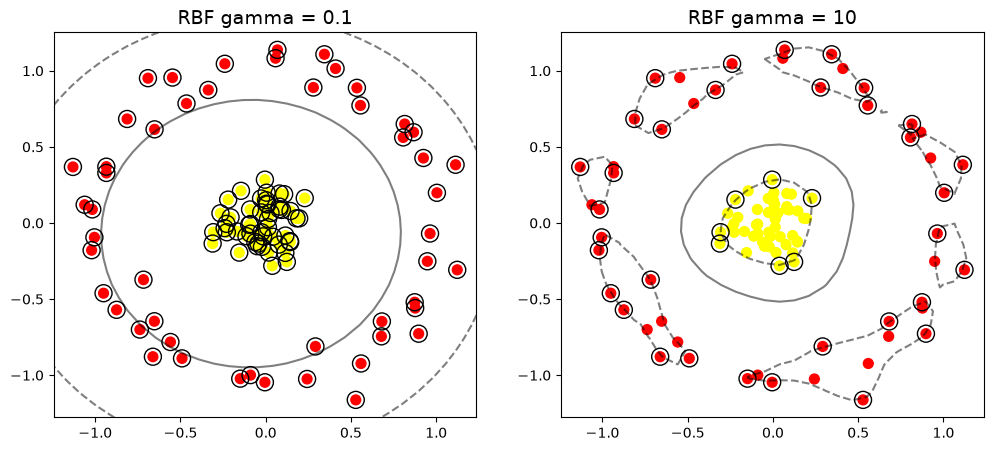

In [3]:
from sklearn.datasets import make_circles

X, y = make_circles(100, factor=.1, noise=.1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for axi, gamma in zip(ax, [0.1, 10]):
    m = SVC(kernel='rbf', gamma=gamma).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc(m, axi)
    axi.set_title('RBF gamma = {0}'.format(gamma), size=14)
plt.show()

Dengan gamma kecil (kiri) batas keputusan lebih halus, sedangkan gamma besar (kanan) membuat batas keputusan sangat tajam mengikuti titik-titik data. Kombinasi C dan gamma yang tepat adalah kunci agar model tidak terlalu kaku ataupun terlalu longgar.